# <a id='toc1_'></a>[Despliegue](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Despliegue](#toc1_)    
  - [Modelo champion](#toc1_1_)    
  - [Embeddings del catálogo](#toc1_2_)    
  - [Búsqueda de productos similares](#toc1_3_)    
  - [Modelo multitarea](#toc1_4_)    
  - [Interpretabilidad del modelo con Grad-CAM](#toc1_5_)    
  - [La app](#toc1_6_)    
  - [Resumen](#toc1_7_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook preparamos lo que necesita la app de Streamlit: cargamos el modelo `champion` desde el Model Registry, calculamos los embeddings de todo el catálogo para buscar productos parecidos y probamos la búsqueda. La app está en `app/streamlit_app.py`.

La app ha ido cambiando con los modelos. La primera versión usaba el modelo de una sola tarea (`masterCategory`). Después pasó al modelo multitarea, que predice también la subcategoría y el tipo de artículo, y ahora usa su versión 2, que añade el color y el género.

**Objetivos:**
1. Cargar el modelo `champion` de una tarea desde el Model Registry de MLflow.
2. Calcular los embeddings de las imágenes del catálogo.
3. Probar la búsqueda de productos similares.
4. Repetir lo mismo con el modelo multitarea, que es el que usa la app ahora.
5. Ver con Grad-CAM en qué zonas de la imagen se fija el modelo.
6. Lanzar la app.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from PIL import Image
from torch.utils.data import DataLoader

from fashion_mlops.config import PROCESSED_DATA_DIR, IMAGES_DIR, RANDOM_STATE, MULTITASK_MODEL_NAME, MEMORIA_FIGS_DIR, IMAGE_SIZE
from fashion_mlops.data.dataset import FashionDataset, get_transforms, make_loaders
from fashion_mlops.data.make_dataset import add_multitask_labels
from fashion_mlops.models.train import get_device
from fashion_mlops.models.multitask import predict_multitask
from fashion_mlops.models.predict import (
    load_champion_model, load_champion_multitask, get_champion_version, predict_image, predict_image_multitask
)
from fashion_mlops.models.embeddings import (
    get_feature_extractor, compute_embeddings, embed_image, find_similar, embeddings_path
)
from fashion_mlops.models.gradcam import grad_cam, overlay_heatmap

In [2]:
BATCH_SIZE = 128
NUM_WORKERS = 4
N_SIMILAR = 6   # productos parecidos que mostramos por consulta
IMAGE_H, IMAGE_W = IMAGE_SIZE   # tamaño de entrada del modelo, para dibujar la imagen igual que el mapa de Grad-CAM

device = get_device()

## <a id='toc1_1_'></a>[Modelo champion](#toc0_)

Empezamos por el modelo de una sola tarea (`fashion-mastercategory`), con el que hicimos la primera versión de la app. Cargamos el que tiene el alias `champion` en el Model Registry. No necesitamos saber de qué experimento viene: eso lo decidimos en `05_mlflow`.

In [3]:
model, classes = load_champion_model()
champion = get_champion_version()

print(f"Modelo: versión {champion.version} (run {champion.tags.get('run_name')})")
print(f"F1-macro en validación: {champion.tags.get('val_f1_macro')} | en test: {champion.tags.get('test_f1_macro')}")
print(f"Clases: {classes}")

Modelo: versión 2 (run fine_tuning_30ep)
F1-macro en validación: 0.8467 | en test: 0.8995
Clases: ['Accessories', 'Apparel', 'Footwear', 'Other', 'Personal Care']


## <a id='toc1_2_'></a>[Embeddings del catálogo](#toc0_)

Para recomendar productos parecidos a la imagen que sube el usuario, quitamos la última capa del modelo. Así, en lugar de las probabilidades de cada clase, el modelo devuelve un vector de 512 números (embedding) que resume el aspecto de la imagen. Dos productos parecidos tendrán vectores parecidos, y lo medimos con la similitud coseno.

Calculamos el embedding de todas las imágenes del catálogo y lo guardamos. Si en el futuro cambia el modelo `champion`, hay que volver a ejecutar esta celda (el fichero lleva el número de versión del modelo).

In [4]:
df = pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv")

extractor = get_feature_extractor(model)

loader = DataLoader(
    FashionDataset(df, IMAGES_DIR, label_col="masterCategory_idx", transform=get_transforms(train=False)),
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
)

embeddings = compute_embeddings(extractor, loader, device)

# El nombre del fichero lleva el modelo registrado y su versión
path = embeddings_path(champion.name, champion.version)
np.savez(path, ids=df["id"].to_numpy(), embeddings=embeddings)

print(f"Embeddings: {embeddings.shape} guardados en {path.name}")

Embeddings: (44414, 512) guardados en embeddings_fashion-mastercategory_v2.npz


## <a id='toc1_3_'></a>[Búsqueda de productos similares](#toc0_)

Probamos con algunas imágenes de test: predecimos su categoría y buscamos los productos más parecidos dentro de esa categoría (quitando la propia imagen):

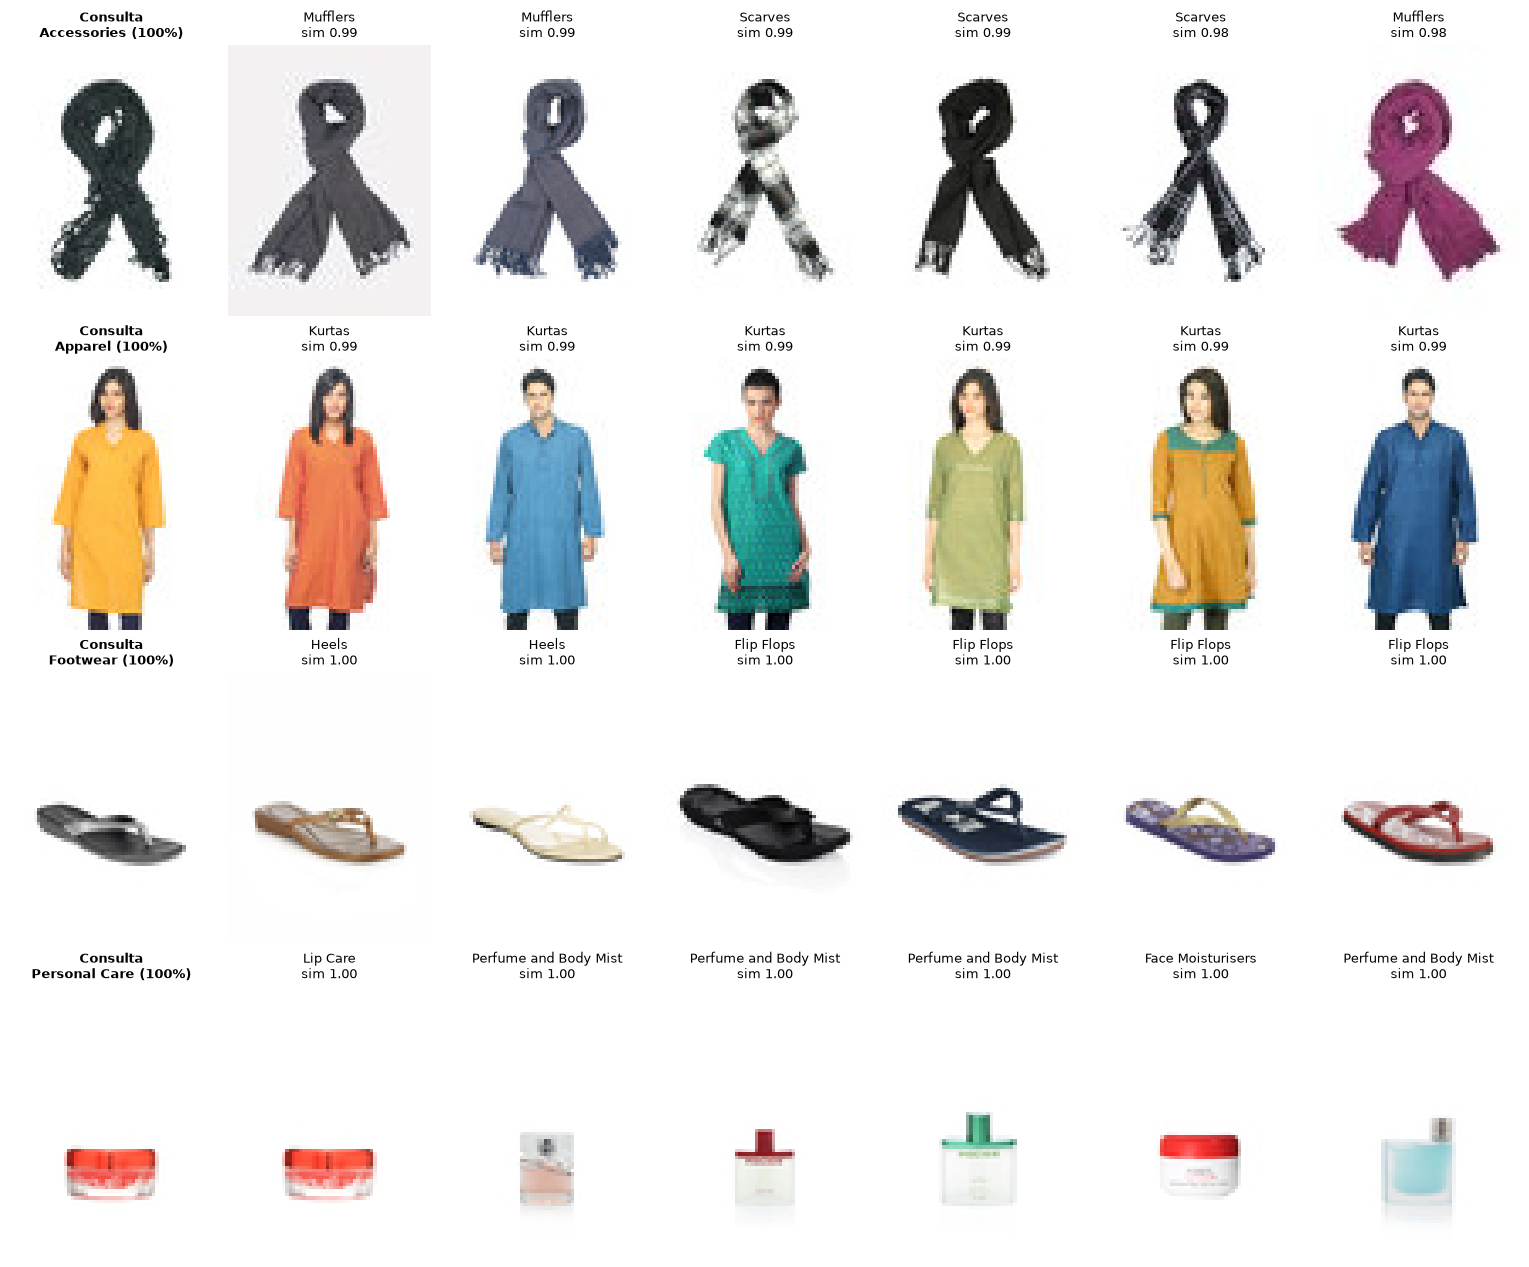

In [5]:
queries = df[df["split"] == "test"].groupby("masterCategory_grouped").sample(1, random_state=RANDOM_STATE)
queries = queries[queries["masterCategory_grouped"] != "Other"]

fig, axes = plt.subplots(len(queries), N_SIMILAR + 1, figsize=(2.2 * (N_SIMILAR + 1), 3.2 * len(queries)))

for row, (_, query) in zip(axes, queries.iterrows()):
    image = Image.open(IMAGES_DIR / f"{query['id']}.jpg")
    probs = predict_image(model, image, classes)
    pred = next(iter(probs))

    mask = (df["masterCategory_grouped"] == pred) & (df["id"] != query["id"])
    similar, similarity = find_similar(embed_image(extractor, image), embeddings, k=N_SIMILAR, mask=mask.to_numpy())

    row[0].imshow(image)
    row[0].set_title(f"Consulta\n{pred} ({probs[pred]:.0%})", fontsize=9, fontweight="bold")

    for ax, idx, sim in zip(row[1:], similar, similarity):
        ax.imshow(Image.open(IMAGES_DIR / f"{df.iloc[idx]['id']}.jpg"))
        ax.set_title(f"{df.iloc[idx]['articleType']}\nsim {sim:.2f}", fontsize=9)

    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.show()

Los productos que devuelve son del mismo tipo que la consulta (bufandas, kurtas, chanclas, cosméticos), aunque no siempre del mismo color: el modelo se fija sobre todo en la forma del producto, que es lo que ha aprendido para clasificar.

Pero solo sabe la categoría, así que solo podemos filtrar por categoría (todos los accesorios, toda la ropa...). Para dar más detalle y buscar mejor, pasamos al modelo multitarea.

## <a id='toc1_4_'></a>[Modelo multitarea](#toc0_)

En `04_modeling` entrenamos un modelo multitarea (`fashion-multitask`) que predice a la vez la categoría, la subcategoría y el tipo de artículo. La app pasó a usarlo, porque da mucho más detalle y permite buscar parecidos **dentro del tipo de artículo predicho**, que es más preciso que buscar dentro de la categoría.

Después entrenamos una versión 2 que añade el **color** y el **género**. En `05_mlflow` la registramos como versión 2 y le pasamos el alias `champion`, así que es la que cargamos aquí y la que usa la app. Calculamos los embeddings del catálogo con su red compartida (el fichero lleva el nombre y la versión del modelo, así que los de cada versión no se pisan).

In [6]:
mt_model, mt_classes = load_champion_multitask()
mt_champion = get_champion_version(name=MULTITASK_MODEL_NAME)

print(f"Modelo: {mt_champion.name} versión {mt_champion.version} (run {mt_champion.tags.get('run_name')})")
print({task: f"F1-macro test {mt_champion.tags.get(f'test_{task}_f1_macro')}" for task in mt_classes})

Modelo: fashion-multitask versión 2 (run multitask_v2_fine_tuning_30ep)
{'masterCategory': 'F1-macro test 0.8694', 'subCategory': 'F1-macro test 0.9377', 'articleType': 'F1-macro test 0.8348', 'baseColour': 'F1-macro test 0.5016', 'gender': 'F1-macro test 0.7795'}


In [7]:
# Etiquetas del modelo multitarea, agrupadas igual que en el entrenamiento
mt_run = mlflow.get_run(mt_champion.run_id)
mt_label_mappings = mlflow.artifacts.load_dict(f"runs:/{mt_champion.run_id}/label_mappings.json")
mt_df = add_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"),
    label_mappings=mt_label_mappings,
    min_count=int(mt_run.data.params["min_train_examples"]),
)

mt_extractor = get_feature_extractor(mt_model)
mt_loader = DataLoader(
    FashionDataset(mt_df, IMAGES_DIR, label_col="masterCategory_idx", transform=get_transforms(train=False)),
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
)

mt_embeddings = compute_embeddings(mt_extractor, mt_loader, device)

mt_path = embeddings_path(mt_champion.name, mt_champion.version)
np.savez(mt_path, ids=mt_df["id"].to_numpy(), embeddings=mt_embeddings)

print(f"Embeddings: {mt_embeddings.shape} guardados en {mt_path.name}")

Embeddings: (44414, 512) guardados en embeddings_fashion-multitask_v2.npz


Probamos la búsqueda con una imagen de test de cada categoría: predecimos todas las tareas y buscamos los productos más parecidos con el mismo tipo de artículo:

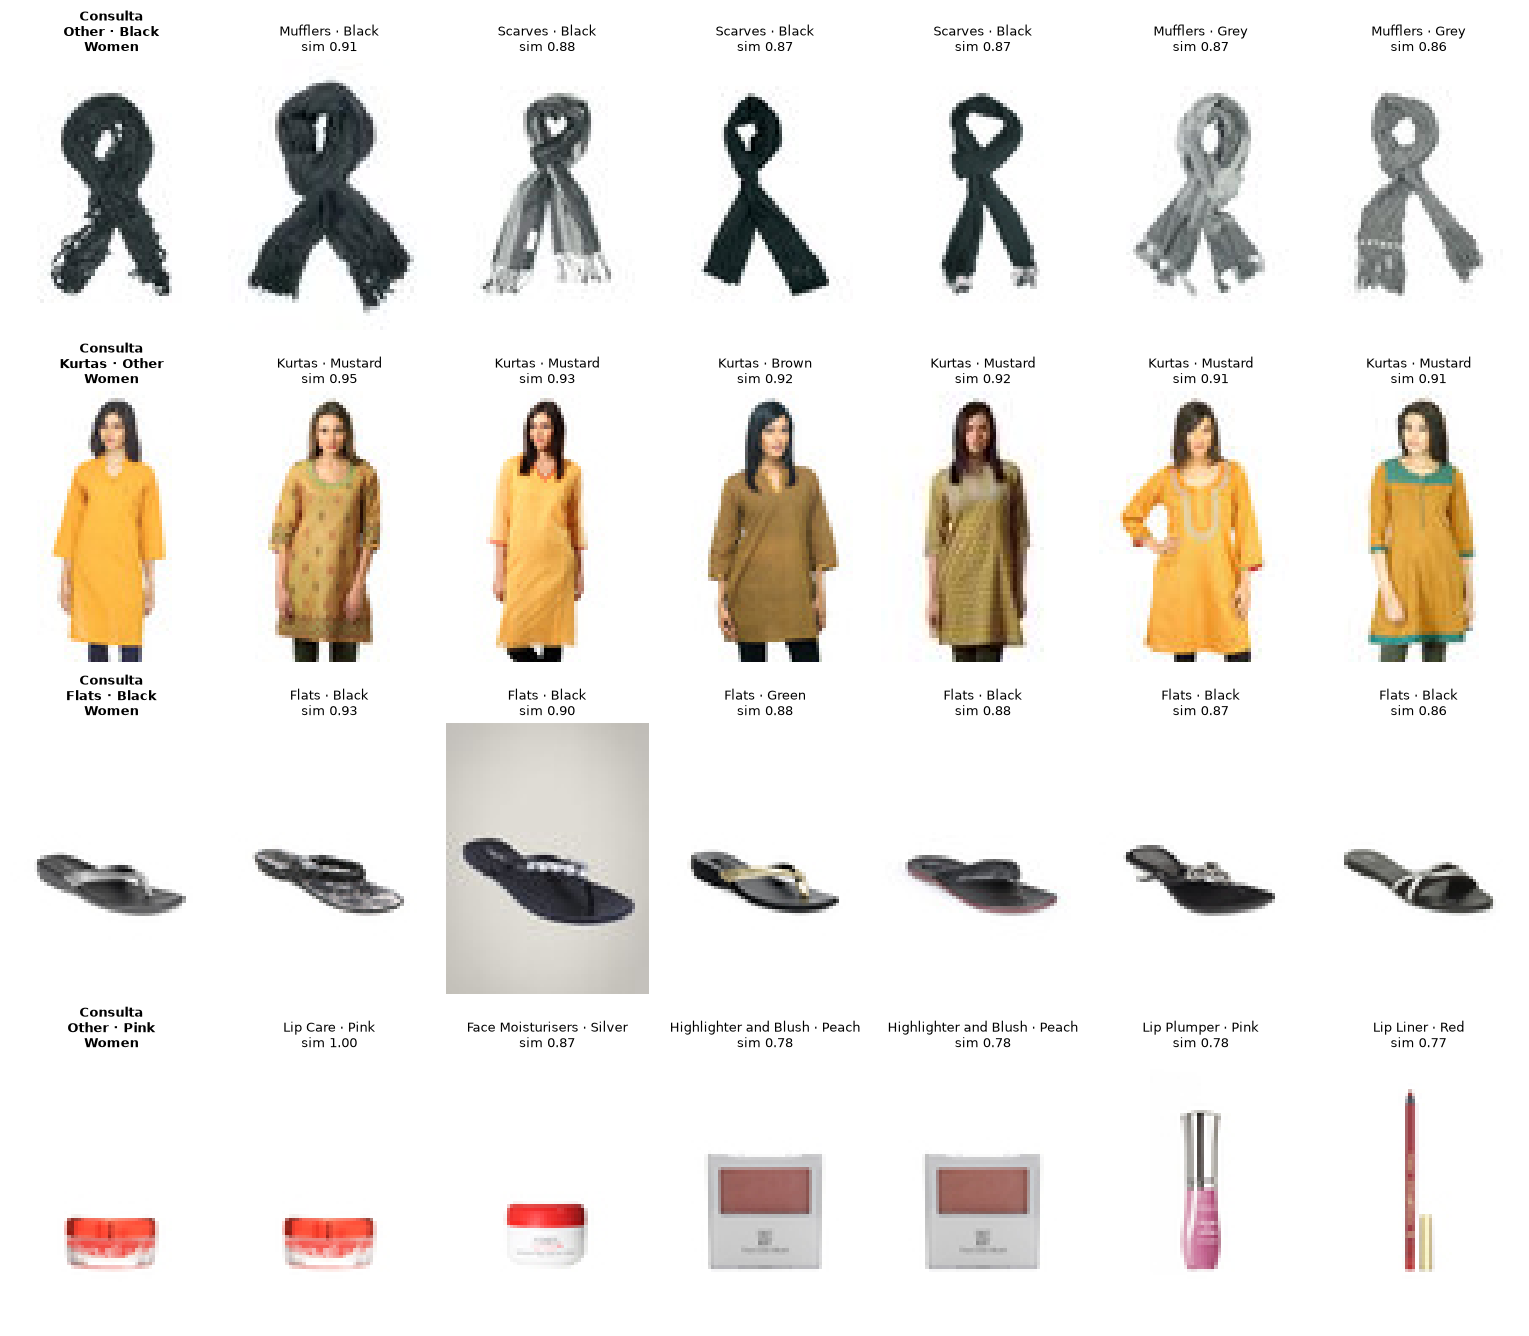

In [8]:
queries = mt_df[mt_df["split"] == "test"].groupby("masterCategory_mt").sample(1, random_state=RANDOM_STATE)
queries = queries[queries["masterCategory_mt"] != "Other"]

fig, axes = plt.subplots(len(queries), N_SIMILAR + 1, figsize=(2.2 * (N_SIMILAR + 1), 3.4 * len(queries)))

for row, (_, query) in zip(axes, queries.iterrows()):
    image = Image.open(IMAGES_DIR / f"{query['id']}.jpg")
    probs = predict_image_multitask(mt_model, image, mt_classes)
    preds = {task: next(iter(probs[task])) for task in probs}

    mask = (mt_df["articleType_mt"] == preds["articleType"]) & (mt_df["id"] != query["id"])
    similar, similarity = find_similar(embed_image(mt_extractor, image), mt_embeddings, k=N_SIMILAR, mask=mask.to_numpy())

    row[0].imshow(image)
    row[0].set_title(f"Consulta\n{preds['articleType']} · {preds['baseColour']}\n{preds['gender']}", fontsize=9, fontweight="bold")

    for ax, idx, sim in zip(row[1:], similar, similarity):
        product = mt_df.iloc[idx]
        ax.imshow(Image.open(IMAGES_DIR / f"{product['id']}.jpg"))
        ax.set_title(f"{product['articleType']} · {product['baseColour']}\nsim {sim:.2f}", fontsize=9)

    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.show()

Los parecidos son muy buenos: bufandas con bufandas, kurtas con kurtas, chanclas con chanclas y cosméticos con cosméticos, y además casi siempre del mismo color que la consulta (bufandas negras, kurtas mostaza, chanclas negras).

Vemos también dos limitaciones:
- La bufanda y la crema tienen tipo `Other` (son tipos con menos de 100 imágenes en train). Aun así los embeddings encuentran productos parecidos, pero el filtro por tipo no ayuda. Por eso la app, cuando el tipo es `Other`, busca dentro de la misma categoría.
- El color de la kurta sale `Other`, porque el mostaza es uno de los colores agrupados por tener pocas imágenes. Aun así, los parecidos son del mismo tono.

## <a id='toc1_5_'></a>[Interpretabilidad del modelo con Grad-CAM](#toc0_)

Para entender por qué acierta o falla el modelo usamos **Grad-CAM** (Selvaraju et al., 2017). A partir de los gradientes de la última capa convolucional calcula cuánto influye cada zona de la imagen en la clase predicha, y lo pintamos encima como un mapa de calor (rojo = más importante). En el modelo multitarea lo podemos hacer para cada tarea por separado.

La última capa convolucional tiene una resolución de solo 7×6, así que el mapa es grueso: nos dice la zona en la que se fija, no el detalle.

Primero calculamos las predicciones del modelo en uso para todo test, para poder elegir aciertos y errores:

In [9]:
mt_tasks = list(mt_classes)
test_loader = make_loaders(
    mt_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in mt_tasks], batch_size=BATCH_SIZE, num_workers=NUM_WORKERS
)["test"]
_, test_pred = predict_multitask(mt_model.to(device), test_loader, device, mt_tasks)
mt_model.cpu()

test_df = mt_df[mt_df["split"] == "test"].reset_index(drop=True)
for task in mt_tasks:
    test_df[f"{task}_pred"] = [mt_classes[task][idx] for idx in test_pred[task]]

Un acierto de cada categoría: para cada uno pintamos dónde mira el modelo para decidir el tipo, el color y el género.

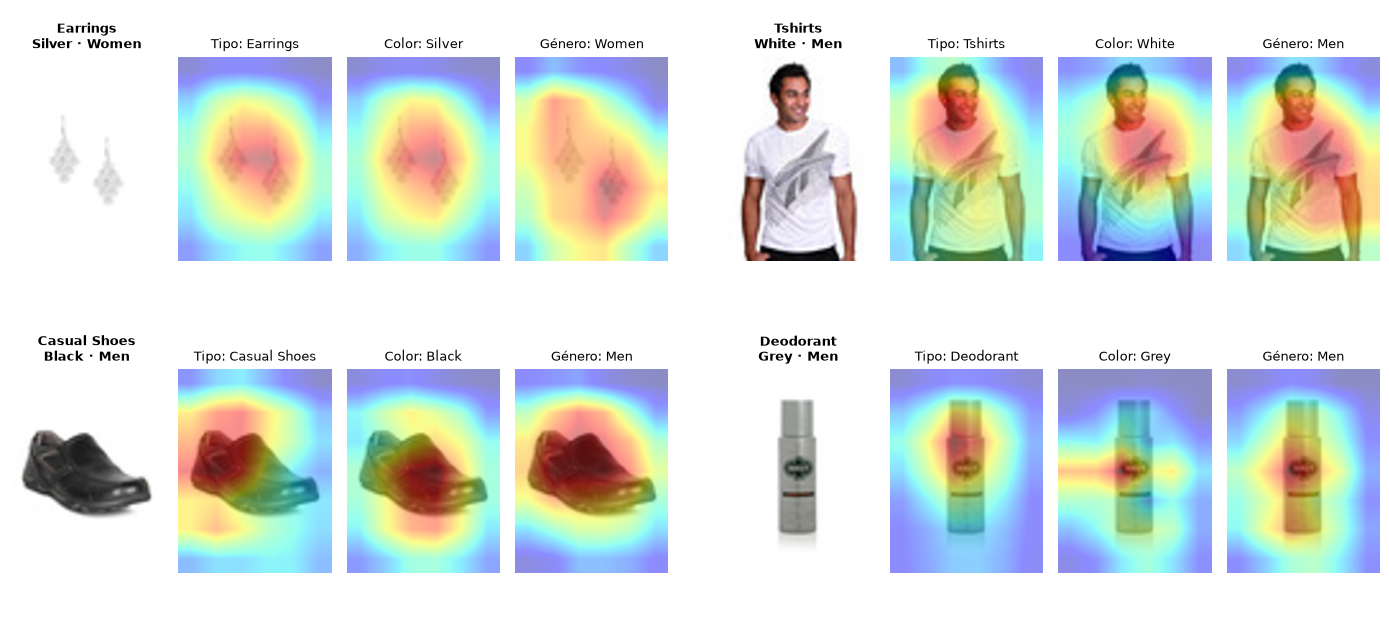

In [12]:
GRADCAM_TASKS = {"articleType": "Tipo", "baseColour": "Color", "gender": "Género"}

# Productos en los que acierta todas las tareas, uno por categoría
all_correct = (test_df[[f"{task}_pred" for task in mt_tasks]].to_numpy() == test_df[[f"{task}_mt" for task in mt_tasks]].to_numpy()).all(axis=1)
hits = test_df[all_correct & (test_df["articleType_mt"] != "Other") & (test_df["masterCategory_mt"] != "Other")]
hits = hits.groupby("masterCategory_mt").sample(1, random_state=RANDOM_STATE)

# Dos productos por fila: imagen y un mapa por tarea, con una columna estrecha de separación en medio
n_cols = len(GRADCAM_TASKS) + 1
fig, axes = plt.subplots(
    2, 2 * n_cols + 1, figsize=(14, 6.4), gridspec_kw={"width_ratios": [1] * n_cols + [0.15] + [1] * n_cols}
)
for ax in axes[:, n_cols]:
    ax.axis("off")

for i, (_, product) in enumerate(hits.iterrows()):
    start = (i % 2) * (n_cols + 1)
    row = axes[i // 2, start:start + n_cols]
    image = Image.open(IMAGES_DIR / f"{product['id']}.jpg")
    row[0].imshow(image.convert("RGB").resize((IMAGE_W, IMAGE_H)))
    row[0].set_title(f"{product['articleType_mt']}\n{product['baseColour_mt']} · {product['gender_mt']}", fontsize=9, fontweight="bold")

    for ax, (task, label) in zip(row[1:], GRADCAM_TASKS.items()):
        cam, idx = grad_cam(mt_model, image, task=task)
        ax.imshow(overlay_heatmap(image, cam))
        ax.set_title(f"{label}: {mt_classes[task][idx]}", fontsize=9)

    for ax in row:
        ax.axis("off")

plt.tight_layout()
fig.savefig(MEMORIA_FIGS_DIR / "gradcam_aciertos.pdf", bbox_inches="tight")
plt.show()

En los aciertos el modelo mira sobre todo el producto y no el fondo: los pendientes, el zapato o el desodorante. Para el color se fija en la zona donde se ve el tono: el centro del zapato o, en el desodorante, una franja a la altura de la etiqueta (que se sale un poco hacia el fondo).

La camiseta es el caso más interesante, porque los mapas no se quedan en la prenda:
- Para el **tipo** se fija en el cuello, que es justo lo que distingue una camiseta de una camisa o un polo.
- Para el **género** el mapa cubre el torso, los hombros y parte de la cara, es decir, la complexión de la persona que lleva la prenda.

Esto apunta a que, para el género, la red usa también a la persona y no solo la prenda. Sería un caso de ***shortcut learning*** (Geirhos et al., 2020): la red aprende una pista fácil que en los datos siempre acompaña a la clase, en lugar de lo que la define. En el catálogo funciona, porque la ropa de hombre la lleva un modelo hombre, y por eso no lo vemos en las métricas (accuracy de género 0,92 en test). Pero con la foto de una prenda sola, o con una prenda unisex que lleva una mujer, se podría equivocar. Con pocos ejemplos no lo podemos asegurar, pero es una limitación a tener en cuenta.

Ahora algunos errores típicos. Para cada uno pintamos el mapa de la tarea en la que se equivoca:

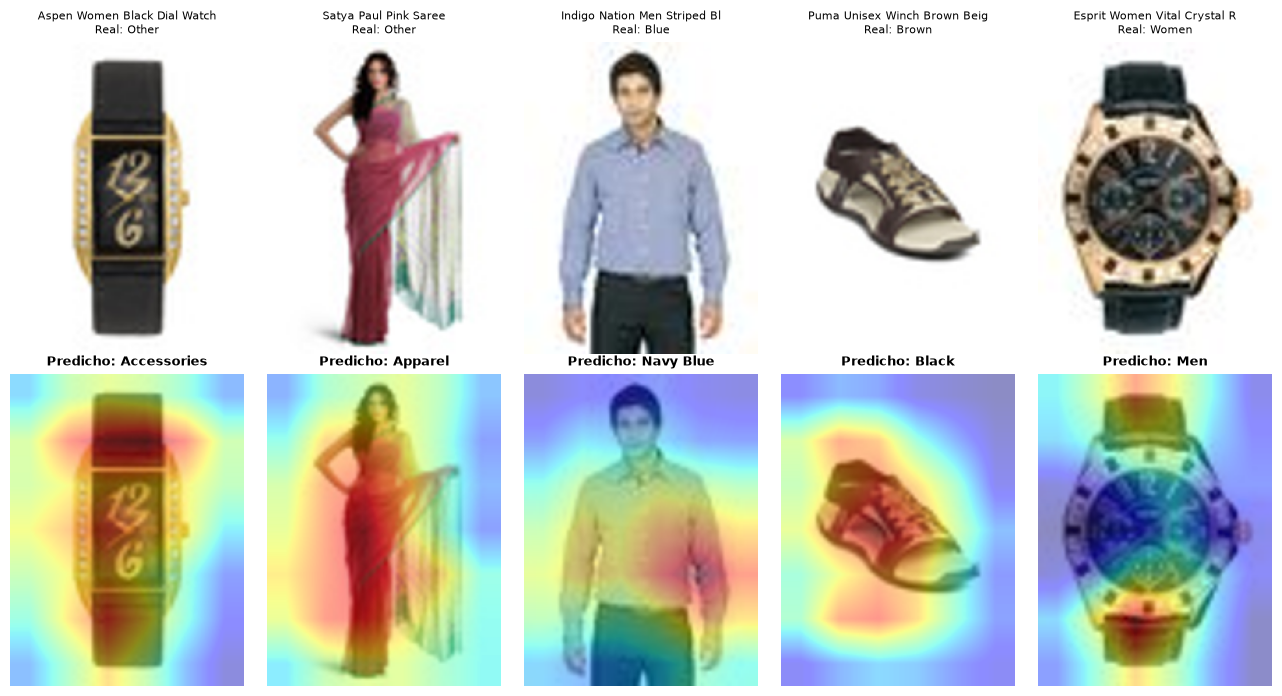

In [11]:
errors = pd.concat([
    # Regalos promocionales (Other) que en realidad son un reloj y un sari
    test_df[(test_df["masterCategory_mt"] == "Other") & (test_df["articleType_pred"] == "Watches")].head(1).assign(task="masterCategory"),
    test_df[(test_df["masterCategory_mt"] == "Other") & (test_df["articleType_pred"] == "Sarees")].head(1).assign(task="masterCategory"),
    # Colores parecidos
    test_df[(test_df["baseColour_mt"] == "Blue") & (test_df["baseColour_pred"] == "Navy Blue") & (test_df["masterCategory_mt"] == "Apparel")].sample(1, random_state=RANDOM_STATE).assign(task="baseColour"),
    test_df[(test_df["baseColour_mt"] == "Brown") & (test_df["baseColour_pred"] == "Black")].sample(1, random_state=RANDOM_STATE).assign(task="baseColour"),
    # Género
    test_df[(test_df["gender_mt"] == "Women") & (test_df["gender_pred"] == "Men")].sample(1, random_state=RANDOM_STATE).assign(task="gender"),
])

fig, axes = plt.subplots(2, len(errors), figsize=(2.6 * len(errors), 7))

for col, (_, product) in zip(axes.T, errors.iterrows()):
    image = Image.open(IMAGES_DIR / f"{product['id']}.jpg")
    cam, idx = grad_cam(mt_model, image, task=product["task"])

    col[0].imshow(image.convert("RGB").resize((IMAGE_W, IMAGE_H)))
    col[0].set_title(f"{product['productDisplayName'][:28]}\nReal: {product[product['task'] + '_mt']}", fontsize=8)
    col[1].imshow(overlay_heatmap(image, cam))
    col[1].set_title(f"Predicho: {mt_classes[product['task']][idx]}", fontsize=9, fontweight="bold")

    for ax in col:
        ax.axis("off")

plt.tight_layout()
fig.savefig(MEMORIA_FIGS_DIR / "gradcam_errores.pdf", bbox_inches="tight")
plt.show()

Los errores también tienen explicación:
- **Reloj y sari etiquetados como `Other`** (regalos promocionales): el modelo mira el producto y dice `Accessories` y `Apparel`, que es lo que son. El error está en la etiqueta, no en el modelo.
- **Camisa azul → azul marino**: el mapa baja hacia la cintura, donde empieza el pantalón oscuro. El color del pantalón se mezcla con el de la camisa.
- **Sandalia marrón y beige → negro**: se fija en las tiras oscuras, que con imágenes tan pequeñas se ven casi negras.
- **Reloj de mujer → hombre**: es un reloj grande y de esfera ancha, como los de hombre. Mira toda la esfera, y por la forma no hay manera de saberlo.

Grad-CAM confirma que el modelo aprende cosas razonables: los errores vienen sobre todo de etiquetas ambiguas o de información que no está en la imagen, y, en el género, de que el modelo se fija en parte en la persona que lleva la prenda. Para comprobarlo y corregirlo, en el futuro habría que evaluar el género con fotos de la prenda sola y recortar la prenda antes de clasificarla.

## <a id='toc1_6_'></a>[La app](#toc0_)

La app (**ModaLens**) está en `app/streamlit_app.py` y se lanza desde la raíz del proyecto con:

```bash
uv run streamlit run app/streamlit_app.py
```

Se abre en el navegador (http://localhost:8501). Ha evolucionado con los modelos:
- **Primera versión**, con el modelo de una tarea: predecía la categoría con la probabilidad de cada clase y mostraba productos parecidos de la misma categoría.
- **Con el modelo multitarea**: pasó a mostrar la ruta completa (categoría › subcategoría › tipo) con la confianza de cada nivel, las otras posibilidades del tipo de artículo y un aviso si los tres niveles no encajan entre sí. Los parecidos se buscan por defecto dentro del mismo tipo.
- **Con el multitarea v2** (la actual): muestra también el color y el género predichos, y se puede buscar entre productos del mismo tipo y color.

Ahora tiene dos páginas:
- **Analizar**: se da la imagen de un producto de cuatro formas (subiéndola, pegando su enlace, pegándola desde el portapapeles o con una imagen aleatoria de test; se analiza siempre la última), y se ven las predicciones y los productos parecidos. Se puede buscar dentro del mismo tipo, del mismo tipo y color, de la misma categoría o en todo el catálogo ("Por forma").
- **Modelos**: métricas en test de los dos modelos registrados, comparación entre ellos, matrices de confusión e historial de versiones, todo leído de MLflow.

La app usa siempre el modelo `champion` del Model Registry: si en `05_mlflow` se registra un modelo mejor, la app lo usa sin cambiar el código (solo hay que recalcular los embeddings con este notebook).

## <a id='toc1_7_'></a>[Resumen](#toc0_)

- **Modelo de una tarea** (`fashion-mastercategory`, versión 2, fine-tuning de 30 épocas, F1-macro 0,899 en test): lo cargamos desde el Model Registry, calculamos los embeddings del catálogo (`embeddings_fashion-mastercategory_v2.npz`) y vimos que la búsqueda devuelve productos del mismo tipo. Fue la base de la primera versión de la app.
- **Modelo multitarea** (`fashion-multitask`): la app pasó a usarlo para dar la ruta completa categoría › subcategoría › tipo y buscar parecidos dentro del mismo tipo.
- **Multitarea v2** (champion actual): añade el color y el género (F1-macro en test: categoría 0,869, subcategoría 0,938, tipo 0,835, color 0,502 y género 0,780). Sus embeddings están en `embeddings_fashion-multitask_v2.npz`.
- **Grad-CAM** muestra que el modelo mira el producto y no el fondo, y explica muchos errores: etiquetas ambiguas (regalos de `Other` que son relojes o saris), colores mezclados con otras prendas y un género que se deduce en parte de la persona que lleva la prenda (posible *shortcut learning*).
- La app de Streamlit (ModaLens) junta todo: analiza la imagen que da el usuario, le muestra productos parecidos del catálogo y enseña las métricas de los modelos, siempre con el modelo que esté marcado como `champion`.

Con esto tenemos el pipeline completo: datos (`01`-`03`), entrenamiento y registro de experimentos (`04` y la comparación con FashionCLIP en `04b`), selección y registro del modelo (`05`) y despliegue en una app (`06`).